# 01 — Introduction to Deep Learning

## From Mathematical Foundations to PyTorch

Welcome to the first notebook in this Deep Learning course.

In this notebook, we will explore the fundamental ideas behind
artificial intelligence, machine learning, and deep learning.

We will begin with intuition and mathematical foundations, then
build our first artificial neuron using NumPy, visualize its behavior,
and introduce the core Tensor operations in PyTorch.

### Topics
- Artificial Intelligence vs. Machine Learning vs. Deep Learning
- Datasets, features, labels, and model predictions
- Artificial neurons and activation functions
- Neural network architecture
- Tensors and basic mathematical operations
- Forward propagation, loss, and gradient descent
- First implementations with NumPy and PyTorch
- Practical applications and exercises

**Prerequisites:** Basic Python programming and familiarity with
variables, functions, lists, and mathematical operations.

## 1. Learning Objectives

By the end of this notebook, you should be able to:

1. Explain the relationship between AI, ML, and DL.
2. Distinguish rule-based programming from machine learning.
3. Identify features, labels, predictions, and datasets.
4. Explain the role of weights, bias, and activation functions.
5. Describe the main layers of a neural network.
6. Understand the basic role of loss and gradient descent.
7. Create and manipulate tensors using PyTorch.
8. Compute a simple neuron output using NumPy.
9. Plot activation functions and a basic training curve.
10. Explain how deep learning can be applied to biological data.

## 2. Environment Setup

We will use the following libraries:

- NumPy: numerical computation
- Matplotlib: data visualization
- PyTorch: tensor computation and automatic differentiation

Install the required libraries if they are not already available.

In [2]:
# Import NumPy for numerical operations.
import numpy as np

# Import Matplotlib for creating plots.
import matplotlib.pyplot as plt

# Import PyTorch for tensor operations and automatic differentiation.
import torch

# Print the installed library versions.
print("NumPy version:", np.__version__)
print("PyTorch version:", torch.__version__)

# Check whether CUDA is available for GPU computation.
print("CUDA available:", torch.cuda.is_available())

# Set a random seed to make NumPy experiments reproducible.
np.random.seed(42)

# Set a random seed for PyTorch experiments.
torch.manual_seed(42)

NumPy version: 2.4.6
PyTorch version: 2.5.1+cu121
CUDA available: True


## 3. Artificial Intelligence, Machine Learning, and Deep Learning

Artificial Intelligence (AI) is the broad field of building systems
that perform tasks associated with intelligent behavior.

Machine Learning (ML) is a subfield of AI in which systems learn
patterns from data rather than relying entirely on manually written
rules.

Deep Learning (DL) is a subfield of machine learning that uses neural
networks with multiple layers to learn increasingly complex
representations of data.

A simplified relationship is:

AI ⊃ ML ⊃ DL

This means that deep learning is part of machine learning, and
machine learning is part of artificial intelligence.

Not every AI system uses machine learning, and not every machine
learning model is a deep neural network.

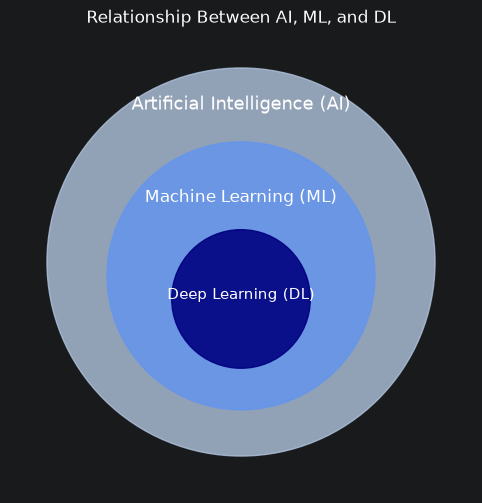

In [3]:
# Create a figure to illustrate the nested relationship between AI, ML, and DL.
fig, ax = plt.subplots(figsize=(9, 6))

# Draw the outer region representing Artificial Intelligence.
ai = plt.Circle((0.5, 0.5), 0.42, color="lightsteelblue", alpha=0.8)
ax.add_patch(ai)

# Draw the middle region representing Machine Learning.
ml = plt.Circle((0.5, 0.47), 0.29, color="cornflowerblue", alpha=0.85)
ax.add_patch(ml)

# Draw the inner region representing Deep Learning.
dl = plt.Circle((0.5, 0.42), 0.15, color="navy", alpha=0.9)
ax.add_patch(dl)

# Add labels to each region.
ax.text(0.5, 0.83, "Artificial Intelligence (AI)", ha="center", fontsize=13)
ax.text(0.5, 0.63, "Machine Learning (ML)", ha="center", fontsize=12)
ax.text(0.5, 0.42, "Deep Learning (DL)", ha="center", color="white", fontsize=11)

# Remove axes for a cleaner diagram.
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
ax.axis("off")

# Add a title and display the figure.
plt.title("Relationship Between AI, ML, and DL")
plt.show()

## 4. Rule-Based Programming vs. Machine Learning

Consider a simplified task: classify a tumor as benign or malignant.

### Rule-Based Approach

A programmer defines explicit rules, for example:

- If tumor size exceeds a threshold, flag the sample.
- If a measured feature exceeds another threshold, change the result.

These rules can be useful, but manually written thresholds may fail
to capture complex relationships.

### Machine Learning Approach

Instead of specifying every rule manually, we provide examples
containing input features and known outcomes.

A learning algorithm uses these examples to estimate a model.

For example:

Input features:
- Tumor radius
- Texture measurements
- Perimeter
- Area

Target label:
- 0: benign
- 1: malignant

This is a simplified educational example, not a clinical diagnostic
system.

## 5. Datasets, Features, and Labels

A dataset is a collection of observations used for analysis or model
development.

In supervised learning:

- **Sample:** One observation.
- **Feature:** An input variable describing the sample.
- **Label:** The target value the model should predict.
- **Prediction:** The output produced by the model.

Suppose a dataset contains measurements from biological samples.

Let the input matrix be:

$$
X \in \mathbb{R}^{n \times d}
$$

where:

- $n$ is the number of samples.
- $d$ is the number of features.

For binary classification, labels can be represented as:

$$
y \in \{0,1\}^{n}
$$

The goal is to learn a function:

$$
f_\theta(X) \approx y
$$

where $\theta$ represents the learnable parameters of the model.

In [4]:
# Generate synthetic measurements for 200 biological samples.
n_samples = 200

# Create a feature representing a normalized measurement.
feature_1 = np.random.normal(loc=0.0, scale=1.0, size=n_samples)

# Create a second feature with a different distribution.
feature_2 = np.random.normal(loc=0.5, scale=1.2, size=n_samples)

# Combine the features into a matrix with shape (200, 2).
X = np.column_stack((feature_1, feature_2))

# Create binary labels using a simple rule with added noise.
noise = np.random.normal(loc=0.0, scale=0.4, size=n_samples)
y = ((feature_1 + feature_2 + noise) > 0.6).astype(int)

# Print the dataset dimensions and a few examples.
print("Feature matrix shape:", X.shape)
print("Label vector shape:", y.shape)
print("First five feature rows:\n", X[:5])
print("First five labels:", y[:5])

Feature matrix shape: (200, 2)
Label vector shape: (200,)
First five feature rows:
 [[ 0.49671415  0.92934483]
 [-0.1382643   1.17294143]
 [ 0.64768854  1.79966149]
 [ 1.52302986  1.76456246]
 [-0.23415337 -1.15320324]]
First five labels: [1 1 1 1 0]


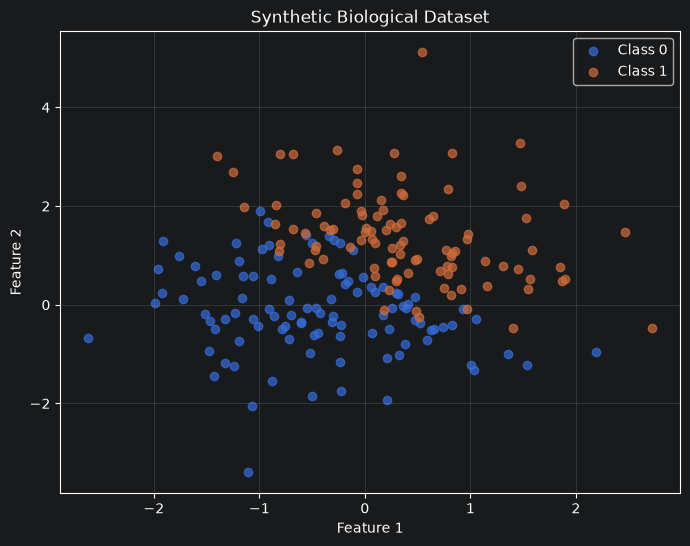

In [5]:
# Create a scatter plot of the two synthetic features.
plt.figure(figsize=(8, 6))

# Plot samples belonging to class 0.
plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Class 0",
    alpha=0.7
)

# Plot samples belonging to class 1.
plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Class 1",
    alpha=0.7
)

# Label the axes and add a title.
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Biological Dataset")

# Display the legend and grid.
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 6. Training, Validation, and Test Sets

Data is commonly divided into three subsets.

### Training Set

Used to learn the model parameters.

### Validation Set

Used during model development to compare configurations and tune
hyperparameters.

### Test Set

Used for a final evaluation after the modeling choices have been
made.

A test set should not repeatedly influence model selection. Doing so
can lead to overly optimistic estimates of generalization.

### Generalization

Generalization is the ability of a trained model to perform well on
previously unseen data.

### Data Leakage

Data leakage occurs when information that would not legitimately be
available at prediction time influences model training or evaluation.

In biological studies, samples from the same patient or closely
related experiments may need to remain in the same split. Otherwise,
the evaluation may overestimate performance.

## 7. The Artificial Neuron

An artificial neuron receives inputs, assigns each input a weight,
adds a bias, and applies an activation function.

For a neuron with $d$ inputs:

$$
z = \sum_{i=1}^{d} w_i x_i + b
$$

In vector notation:

$$
z = \mathbf{w}^{T}\mathbf{x} + b
$$

The final output is:

$$
\hat{y} = \phi(z)
$$

where:

- $\mathbf{x}$ is the input vector.
- $\mathbf{w}$ is the weight vector.
- $b$ is the bias.
- $z$ is the weighted sum before activation.
- $\phi$ is the activation function.
- $\hat{y}$ is the predicted output.

Weights determine how strongly inputs influence the result.
The bias shifts the weighted sum.
The activation function transforms the weighted sum into the
neuron's output.

In [7]:
# Define two input features for one sample.
inputs = np.array([0.8, -0.4])

# Define one weight for each input feature.
weights = np.array([0.7, 0.2])

# Define the bias term.
bias = 0.1

# Calculate the weighted sum before activation.
z = np.dot(weights, inputs) + bias

# Apply the sigmoid activation function.
output = 1 / (1 + np.exp(-z))

# Display the intermediate and final values.
print("Weighted sum:", z)
print("Neuron output:", output)

Weighted sum: 0.58
Neuron output: 0.6410674063348171


## 8. Activation Functions

Activation functions introduce nonlinearity into neural networks.

Without suitable nonlinear activations, stacking ordinary linear
layers would still represent a linear transformation.

### Sigmoid

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

The sigmoid function maps real values into the interval $(0,1)$.
It is often useful for producing a binary classification probability
from a single logit.

### ReLU

$$
\operatorname{ReLU}(z) = \max(0,z)
$$

ReLU is widely used in hidden layers because it is simple and
computationally efficient.

### Tanh

$$
\tanh(z) = \frac{e^z-e^{-z}}{e^z+e^{-z}}
$$

Tanh maps values into the interval $(-1,1)$.

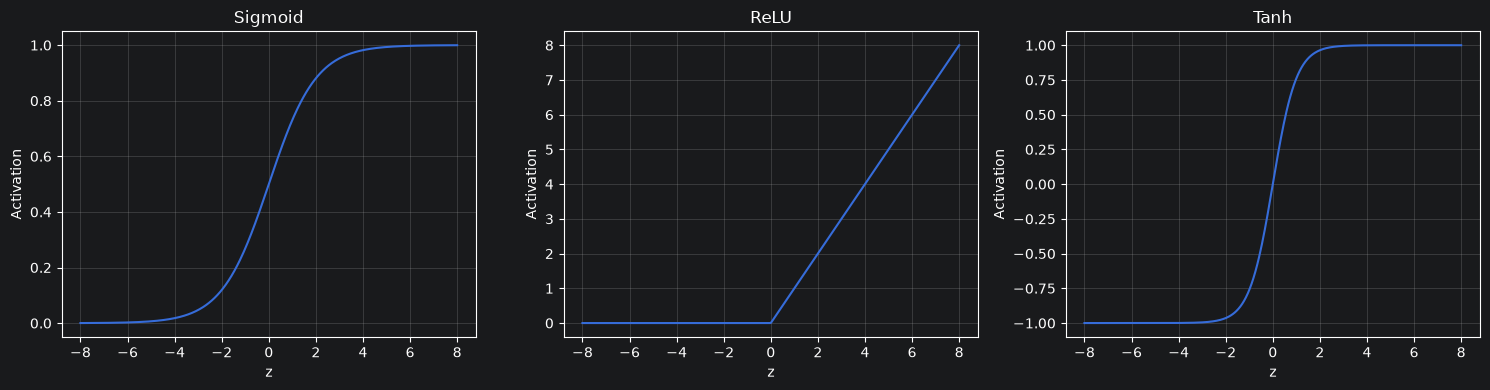

In [8]:
# Generate a range of values for the input to each activation function.
z = np.linspace(-8, 8, 400)

# Compute the sigmoid activation values.
sigmoid = 1 / (1 + np.exp(-z))

# Compute the ReLU activation values.
relu = np.maximum(0, z)

# Compute the tanh activation values.
tanh = np.tanh(z)

# Create three separate subplots for comparison.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Plot the sigmoid function.
axes[0].plot(z, sigmoid)
axes[0].set_title("Sigmoid")
axes[0].set_xlabel("z")
axes[0].set_ylabel("Activation")
axes[0].grid(alpha=0.3)

# Plot the ReLU function.
axes[1].plot(z, relu)
axes[1].set_title("ReLU")
axes[1].set_xlabel("z")
axes[1].set_ylabel("Activation")
axes[1].grid(alpha=0.3)

# Plot the tanh function.
axes[2].plot(z, tanh)
axes[2].set_title("Tanh")
axes[2].set_xlabel("z")
axes[2].set_ylabel("Activation")
axes[2].grid(alpha=0.3)

# Adjust spacing and display the plots.
plt.tight_layout()
plt.show()

## 9. Neural Network Architecture

A basic feed-forward neural network contains three types of layers.

### Input Layer

Receives the input features.

### Hidden Layers

Transform inputs into learned intermediate representations.

### Output Layer

Produces the final prediction.

A neural network with one hidden layer can be represented as:

$$
\mathbf{h} = \phi(W_1\mathbf{x}+\mathbf{b}_1)
$$

$$
\hat{\mathbf{y}} = \psi(W_2\mathbf{h}+\mathbf{b}_2)
$$

Here:

- $W_1$ and $W_2$ are weight matrices.
- $\mathbf{b}_1$ and $\mathbf{b}_2$ are bias vectors.
- $\phi$ is a hidden-layer activation.
- $\psi$ is an output transformation chosen for the task.

The output transformation depends on the problem. For example,
binary classification often uses a sigmoid probability at inference,
while multiclass classification commonly uses softmax probabilities.

## 10. Learnable Parameters

Consider a fully connected layer with:

- $n_{\text{in}}$ input features
- $n_{\text{out}}$ output units

Each output unit has one weight per input and one bias.

The total number of learnable parameters is:

$$
N_{\text{parameters}}
= n_{\text{in}}n_{\text{out}} + n_{\text{out}}
$$

Equivalently:

$$
N_{\text{parameters}}
= (n_{\text{in}}+1)n_{\text{out}}
$$

This count helps us understand model capacity and computational
requirements.

In [9]:
# Define the number of input features and output units.
n_inputs = 10
n_outputs = 4

# Calculate the number of weights in a fully connected layer.
n_weights = n_inputs * n_outputs

# Calculate the number of bias parameters.
n_biases = n_outputs

# Calculate the total number of learnable parameters.
total_parameters = n_weights + n_biases

# Display the results.
print("Number of weights:", n_weights)
print("Number of biases:", n_biases)
print("Total learnable parameters:", total_parameters)

Number of weights: 40
Number of biases: 4
Total learnable parameters: 44


## 11. Scalars, Vectors, Matrices, and Tensors

A scalar is a single number.

A vector is a one-dimensional collection of numbers.

A matrix is a two-dimensional array.

A tensor is a generalization of these structures to arbitrary
numbers of dimensions.

Examples:

- Scalar: one temperature measurement
- Vector: measurements from one sample
- Matrix: features from many samples
- 3D tensor: a batch of color images
- 4D tensor: a batch of volumetric images

In PyTorch, tensors are the fundamental data structure used for
model inputs, parameters, intermediate activations, and gradients.

The shape of a tensor tells us the size of each dimension.

In [10]:
# Create a scalar tensor.
scalar = torch.tensor(3.0)

# Create a one-dimensional tensor.
vector = torch.tensor([1.0, 2.0, 3.0])

# Create a two-dimensional tensor.
matrix = torch.tensor([
    [1.0, 2.0],
    [3.0, 4.0]
])

# Create a tensor containing random values with shape (2, 3).
random_tensor = torch.rand(2, 3)

# Print each tensor and its shape.
print("Scalar:", scalar, "| Shape:", scalar.shape)
print("Vector:", vector, "| Shape:", vector.shape)
print("Matrix:\n", matrix, "| Shape:", matrix.shape)
print("Random tensor:\n", random_tensor)
print("Random tensor shape:", random_tensor.shape)

Scalar: tensor(3.) | Shape: torch.Size([])
Vector: tensor([1., 2., 3.]) | Shape: torch.Size([3])
Matrix:
 tensor([[1., 2.],
        [3., 4.]]) | Shape: torch.Size([2, 2])
Random tensor:
 tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009]])
Random tensor shape: torch.Size([2, 3])


## 12. Forward Propagation

Forward propagation is the process of passing inputs through a
neural network to obtain predictions.

For a simple model:

1. Receive the input features.
2. Multiply the inputs by the model weights.
3. Add the bias.
4. Apply an activation function.
5. Produce the prediction.

The mathematical expression for a single neuron is:

$$
z = \mathbf{w}^{T}\mathbf{x}+b
$$

$$
\hat{y} = \phi(z)
$$

During forward propagation, the model uses its current parameters.
No parameter update is required to calculate the prediction.

## 13. Loss Functions

A loss function quantifies the difference between a model's
prediction and the target.

For regression, a common choice is Mean Squared Error:

$$
L_{\text{MSE}} =
\frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)^2
$$

For binary classification, Binary Cross-Entropy is commonly used
with predicted probabilities:

$$
L_{\text{BCE}} =
-\frac{1}{n}\sum_{i=1}^{n}
\left[
y_i\log(\hat{y}_i)
+(1-y_i)\log(1-\hat{y}_i)
\right]
$$

The appropriate loss depends on the task and the model's output
representation.

A loss value is not, by itself, a complete measure of model quality.
We will study evaluation metrics in a later notebook.

## 14. How Does a Neural Network Learn?

A model learns by adjusting its parameters to reduce the loss.

Gradient descent updates a parameter using:

$$
\theta_{t+1} =
\theta_t-\eta\nabla_\theta L(\theta_t)
$$

where:

- $\theta_t$ represents the current parameters.
- $\eta$ is the learning rate.
- $\nabla_\theta L$ is the gradient of the loss with respect to
  the parameters.
- $\theta_{t+1}$ represents the updated parameters.

The gradient indicates the direction of steepest local increase
in the loss. Gradient descent moves in the opposite direction.

Backpropagation efficiently computes gradients throughout a neural
network by applying the chain rule.

The training loop typically repeats these steps:

1. Forward pass
2. Calculate loss
3. Compute gradients
4. Update parameters
5. Repeat for subsequent batches and epochs

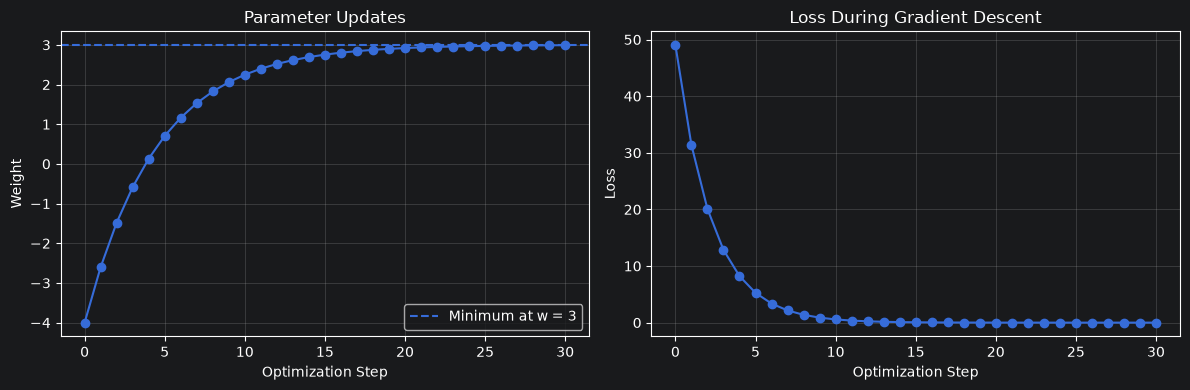

Final weight: 2.9913344197250025
Final loss: 7.509228150242629e-05


In [11]:
# Define a simple quadratic loss function.
def loss_function(w):
    # Calculate the squared distance from the minimum at w = 3.
    return (w - 3) ** 2

# Define the derivative of the loss function.
def loss_gradient(w):
    # Differentiate (w - 3)^2 with respect to w.
    return 2 * (w - 3)

# Initialize the parameter away from the minimum.
w = -4.0

# Set the learning rate and number of optimization steps.
learning_rate = 0.1
n_steps = 30

# Store the parameter and loss values at every step.
weight_history = [w]
loss_history = [loss_function(w)]

# Perform gradient descent.
for step in range(n_steps):
    # Calculate the gradient at the current parameter value.
    gradient = loss_gradient(w)

    # Update the parameter in the opposite direction of the gradient.
    w = w - learning_rate * gradient

    # Record the updated parameter and corresponding loss.
    weight_history.append(w)
    loss_history.append(loss_function(w))

# Create plots of parameter updates and loss reduction.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot the parameter value at each optimization step.
axes[0].plot(weight_history, marker="o")
axes[0].axhline(3, linestyle="--", label="Minimum at w = 3")
axes[0].set_title("Parameter Updates")
axes[0].set_xlabel("Optimization Step")
axes[0].set_ylabel("Weight")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot how the loss decreases over time.
axes[1].plot(loss_history, marker="o")
axes[1].set_title("Loss During Gradient Descent")
axes[1].set_xlabel("Optimization Step")
axes[1].set_ylabel("Loss")
axes[1].grid(alpha=0.3)

# Display both plots.
plt.tight_layout()
plt.show()

# Print the final parameter and loss.
print("Final weight:", w)
print("Final loss:", loss_function(w))

Optimized weight: 2.9913344383239746


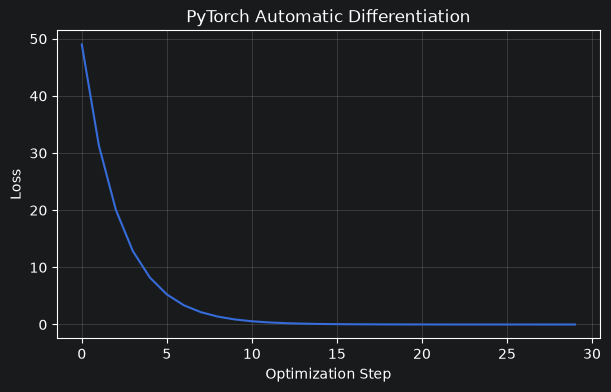

In [12]:
# Create a scalar parameter and enable gradient tracking.
w = torch.tensor(-4.0, requires_grad=True)

# Define the learning rate.
learning_rate = 0.1

# Store loss values for visualization.
loss_values = []

# Perform a small gradient descent experiment.
for step in range(30):
    # Calculate the loss for the current parameter.
    loss = (w - 3) ** 2

    # Save a detached loss value for plotting.
    loss_values.append(loss.item())

    # Calculate the gradient of the loss with respect to w.
    loss.backward()

    # Update the parameter without tracking the update operation.
    with torch.no_grad():
        w -= learning_rate * w.grad

    # Reset the gradient before the next iteration.
    w.grad.zero_()

# Display the optimized parameter.
print("Optimized weight:", w.item())

# Plot the loss values recorded during optimization.
plt.figure(figsize=(7, 4))
plt.plot(loss_values)
plt.title("PyTorch Automatic Differentiation")
plt.xlabel("Optimization Step")
plt.ylabel("Loss")
plt.grid(alpha=0.3)
plt.show()

## 15. NumPy vs. PyTorch

NumPy is excellent for general numerical computation and for
implementing small algorithms from scratch.

PyTorch provides tensor operations designed for deep learning,
automatic differentiation, and accelerator support.

| Capability | NumPy | PyTorch |
|---|---|---|
| Numerical arrays | Yes | Yes |
| Automatic differentiation | Not built in | Yes |
| GPU acceleration | Not its main focus | Supported |
| Neural network modules | No built-in framework | `torch.nn` |
| Optimizers | Manual implementation or other tools | `torch.optim` |

Understanding NumPy first helps clarify the mathematics.
PyTorch then makes it practical to train larger neural networks.

## 16. Deep Learning in Bioinformatics

Deep learning can be applied to many types of biological data,
including:

- DNA and RNA sequences
- Gene expression matrices
- Protein sequences and structures
- Microscopy and medical images
- Multimodal biomedical datasets

For example, a model might use gene expression measurements to
predict a biological class.

However, biomedical datasets often contain challenges such as:

- High-dimensional features
- Small sample sizes
- Class imbalance
- Batch effects
- Related samples from the same patient
- Limited generalization across institutions

A high training score does not establish clinical validity.
A real study requires careful validation, suitable metrics,
transparent reporting, and appropriate domain expertise.

The synthetic data in this notebook is for learning only.

## 17. Summary

In this notebook, we learned that:

- Deep learning is a subfield of machine learning.
- Supervised learning uses examples with known target labels.
- A neuron combines inputs, weights, and a bias.
- Activation functions introduce nonlinear behavior.
- Neural networks contain input, hidden, and output layers.
- Tensors are the core data structures in PyTorch.
- Loss functions measure prediction error.
- Backpropagation calculates gradients.
- Gradient descent updates model parameters.
- NumPy helps us understand computations from scratch.
- PyTorch provides automatic differentiation and neural network tools.

The next notebook will focus on the mathematical foundations
needed to understand neural networks in greater depth.

## 18. Exercises

### Exercise 1 — Concepts

Explain the difference between AI, machine learning, and deep learning.

### Exercise 2 — Neuron Calculation

Given:

- Inputs: $x_1=0.5$, $x_2=1.5$
- Weights: $w_1=0.8$, $w_2=-0.2$
- Bias: $b=0.1$

Calculate the weighted sum:

$$
z=w_1x_1+w_2x_2+b
$$

Then calculate the sigmoid output.

### Exercise 3 — Activation Functions

Plot sigmoid, tanh, and ReLU on separate figures.
Describe how their outputs differ for negative and positive inputs.

### Exercise 4 — Parameter Counting

Calculate the number of learnable parameters in a fully connected
layer with 32 input features and 16 output units.

### Exercise 5 — PyTorch Tensors

Create a tensor with shape `(4, 3)`.
Calculate its mean, maximum, and sum.

### Exercise 6 — Gradient Descent

Change the learning rate in the gradient descent experiment.
Compare how quickly the parameter approaches the minimum.

### Exercise 7 — Biological Application

Suggest one biological prediction task.
Identify possible features, the target label, and a suitable
evaluation strategy.

### Challenge

Implement a single artificial neuron using NumPy and compare its
output with an equivalent computation using PyTorch.

## 19. Function Cheat Sheet

### NumPy
- `np.array()` — Create an array
- `np.dot()` — Compute a dot product
- `np.column_stack()` — Combine arrays as columns
- `np.linspace()` — Generate evenly spaced values
- `np.maximum()` — Compute element-wise maximum
- `np.tanh()` — Apply the hyperbolic tangent

### Matplotlib
- `plt.figure()` — Create a figure
- `plt.subplots()` — Create a figure and axes
- `plt.plot()` — Plot lines
- `plt.scatter()` — Plot points
- `plt.xlabel()` / `plt.ylabel()` — Label axes
- `plt.legend()` — Display a legend
- `plt.grid()` — Display a grid
- `plt.show()` — Display the figure

### PyTorch
- `torch.tensor()` — Create a tensor
- `torch.rand()` — Generate random tensor values
- `.shape` — Inspect tensor dimensions
- `.item()` — Extract a scalar value
- `.backward()` — Calculate gradients
- `torch.no_grad()` — Disable gradient tracking in a block
- `torch.manual_seed()` — Set the PyTorch random seed